In [ ]:
import requests

# 1. Veriyi Kaynaktan İndirme
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt" 

# Project Gutenberg'den temizlenmiş metni alıyoruz:
url_oz = "https://gutenberg.org/cache/epub/55/pg55.txt"

try:
    response = requests.get(url_oz)
    text = response.text
    # Gutenberg başlık ve alt bilgilerini temizlemek (Basit bir dilimleme)
    # Gerçek projelerde daha hassas temizlik gerekebilir.
    start_idx = text.find("*** START OF THE PROJECT GUTENBERG EBOOK") 
    end_idx = text.find("*** END OF THE PROJECT GUTENBERG EBOOK")
    text = text[start_idx + 40 : end_idx] 
    
    print(f"Veri seti başarıyla indirildi. Karakter uzunluğu: {len(text)}")
    print("Metinden bir örnek:\n", text[1000:1200])
except Exception as e:
    print(f"Veri indirilirken hata oluştu: {e}")

Veri seti başarıyla indirildi. Karakter uzunluğu: 212613
Metinden bir örnek:
  China Country
 Chapter XXI. The Lion Becomes the King of Beasts
 Chapter XXII. The Country of the Quadlings
 Chapter XXIII. Glinda The Good Witch Grants Dorothy’s Wish
 Chapter XXIV. Home Again



In [2]:
# 2. Sözlük (Vocabulary) Oluşturma
# Metindeki tüm benzersiz karakterleri bulup sıralıyoruz.
chars = sorted(list(set(text))) 
vocab_size = len(chars)

print(f"Benzersiz karakterler ({vocab_size} adet): {''.join(chars)}")

# 3. Kodlayıcı ve Kod Çözücü (Encoder & Decoder)
# Karakterden tamsayıya dönüşüm (Mapping)
stoi = { ch:i for i,ch in enumerate(chars) }
# Tamsayıdan karaktere dönüşüm
itos = { i:ch for i,ch in enumerate(chars) }

# Metni sayı dizisine çeviren fonksiyon (Encoder)
encode = lambda s: [stoi[c] for c in s] 
# Sayı dizisini metne çeviren fonksiyon (Decoder)
decode = lambda l: ''.join([itos[i] for i in l])

# Test edelim
test_string = "Hello Oz"
encoded = encode(test_string)
decoded = decode(encoded)

print(f"\nOrijinal: {test_string}")
print(f"Encoded : {encoded}")
print(f"Decoded : {decoded}")

Benzersiz karakterler (76 adet): 
 !&()*,-.019:;?ABCDEFGHIJKLMNOPQRSTUVWXYZ[]abcdefghijklmnopqrstuvwxyz—‘’“”

Orijinal: Hello Oz
Encoded : [24, 49, 56, 56, 59, 2, 31, 70]
Decoded : Hello Oz


In [3]:
import torch

# Veriyi PyTorch Tensörüne çevirme
# dtype=torch.long -> Tamsayı (integer) formatında tutuyoruz
data = torch.tensor(encode(text), dtype=torch.long)

# Veriyi ayırma (%90 Train, %10 Val)
n = int(0.9 * len(data)) 
train_data = data[:n]
val_data = data[n:]

print(f"Eğitim Seti Boyutu: {len(train_data)} token")
print(f"Doğrulama Seti Boyutu: {len(val_data)} token")

Eğitim Seti Boyutu: 191351 token
Doğrulama Seti Boyutu: 21262 token


In [4]:
# Eğer Nvidia GPU varsa 'cuda', Mac M1/M2 varsa 'mps', yoksa 'cpu'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Eğitim cihazı: {device}")

# Hiperparametreler (Modelin ayarları)
batch_size = 4    # Her adımda kaç farklı cümle işlenecek?
block_size = 8    # Model geriye dönük kaç harfe bakacak?

Eğitim cihazı: cpu


In [5]:
torch.manual_seed(1337) # Sonuçların tekrar edilebilir olması için tohum sabitleme

def get_batch(split):
    # 1. Veri Kaynağını Seç
    data_src = train_data if split == 'train' else val_data
    
    # 2. Rastgele Başlangıç Noktaları Seç
    ix = torch.randint(len(data_src) - block_size, (batch_size,))
    
    # 3. Girdi (x) ve Hedef (y) Bloklarını Oluştur
    x = torch.stack([data_src[i : i+block_size] for i in ix])
    y = torch.stack([data_src[i+1 : i+block_size+1] for i in ix])
    
    # 4. Veriyi GPU'ya Taşı
    return x.to(device), y.to(device)

In [6]:
xb, yb = get_batch('train')

print("GİRDİLER (x) - Boyut:", xb.shape)
print(xb)
print("\nHEDEFLER (y) - Boyut:", yb.shape)
print(yb)

print("\n--- Modelin Gözünden Eğitim Örneği ---")
# İlk batch'in içindeki ilk diziyi inceleyelim
for t in range(block_size):
    context = xb[0, :t+1].tolist()
    target = yb[0, t].item()
    print(f"Girdi: {context} ({decode(context)}) ---> Hedef: {target} ('{decode([target])}')")

GİRDİLER (x) - Boyut: torch.Size([4, 8])
tensor([[49,  2, 63, 60, 62, 45, 58, 51],
        [53, 58, 55, 53, 58, 51,  2, 64],
        [45, 58, 63, 45, 63, 16, 75,  2],
        [45, 63, 55, 49, 48,  2, 20, 59]])

HEDEFLER (y) - Boyut: torch.Size([4, 8])
tensor([[ 2, 63, 60, 62, 45, 58, 51,  2],
        [58, 55, 53, 58, 51,  2, 64, 52],
        [58, 63, 45, 63, 16, 75,  2, 63],
        [63, 55, 49, 48,  2, 20, 59, 62]])

--- Modelin Gözünden Eğitim Örneği ---
Girdi: [49] (e) ---> Hedef: 2 (' ')
Girdi: [49, 2] (e ) ---> Hedef: 63 ('s')
Girdi: [49, 2, 63] (e s) ---> Hedef: 60 ('p')
Girdi: [49, 2, 63, 60] (e sp) ---> Hedef: 62 ('r')
Girdi: [49, 2, 63, 60, 62] (e spr) ---> Hedef: 45 ('a')
Girdi: [49, 2, 63, 60, 62, 45] (e spra) ---> Hedef: 58 ('n')
Girdi: [49, 2, 63, 60, 62, 45, 58] (e spran) ---> Hedef: 51 ('g')
Girdi: [49, 2, 63, 60, 62, 45, 58, 51] (e sprang) ---> Hedef: 2 (' ')


In [10]:

chars = sorted(list(set(text))) # Metindeki tüm benzersiz karakterleri tekrar bul
vocab_size = len(chars)         

print(f"Güncel Sözlük Boyutu: {vocab_size}")

stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode = lambda s: [stoi[c] for c in s]

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

token_embedding_table = nn.Embedding(vocab_size, n_embd).to(device)

xb, yb = get_batch('train')
tok_emb = token_embedding_table(xb)

print(f"Girdi Boyutu: {xb.shape} -> (Batch, Time)")
print(f"Embedding Çıktısı: {tok_emb.shape} -> (Batch, Time, Channels)")

Güncel Sözlük Boyutu: 76
Girdi Boyutu: torch.Size([4, 8]) -> (Batch, Time)
Embedding Çıktısı: torch.Size([4, 8, 32]) -> (Batch, Time, Channels)


In [11]:
# Block size (Bağlam uzunluğu) kadar pozisyon öğrenmemiz lazım
block_size = 8 

# Pozisyon Embedding Tablosu
# 0'dan 7'ye kadar her pozisyon için 32 boyutlu bir vektör
position_embedding_table = nn.Embedding(block_size, n_embd)

# Pozisyon İndekslerini Oluşturma
# [0, 1, 2, 3, 4, 5, 6, 7]
pos_idx = torch.arange(block_size, device=device) 

# Pozisyon vektörlerini al
pos_emb = position_embedding_table(pos_idx) 

print(f"Pozisyon Embedding Boyutu: {pos_emb.shape} -> (Time, Channels)")

Pozisyon Embedding Boyutu: torch.Size([8, 32]) -> (Time, Channels)


In [12]:
# Girdi olarak modele giren nihai veri (x)
x = tok_emb + pos_emb 

print(f"Modele Giren Veri Boyutu: {x.shape} -> (Batch, Time, Channels)")

Modele Giren Veri Boyutu: torch.Size([4, 8, 32]) -> (Batch, Time, Channels)


In [13]:
import torch.nn.functional as F

# Hiperparametreler (Örnek değerler)
head_size = 16  # Her bir dikkat kafasının vektör boyutu
n_embd = 32     # Ana embedding boyutu
block_size = 8  # Bağlam uzunluğu
dropout = 0.1   # Aşırı öğrenmeyi (overfitting) engellemek için

class Head(nn.Module):
    """ Tek bir Self-Attention Başlığı """
    
    def __init__(self, head_size):
        super().__init__()
        # Q, K, V için Lineer Katmanlar (Projeksiyonlar)
        # bias=False tercih edilir çünkü sadece yön (vektör açısı) önemlidir.
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        
        # Maskeleme Matrisi (Buffer olarak kaydediyoruz, parametre değil)
        # 'tril': Triangle Lower (Alt üçgen matris) -> 1'ler geçmişi, 0'lar geleceği temsil eder.
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # x boyutu: (Batch, Time, Channels) -> (B, T, C)
        B, T, C = x.shape
        
        # 1. Q, K, V vektörlerini üret
        k = self.key(x)   # (B, T, head_size)
        q = self.query(x) # (B, T, head_size)
        
        # 2. Dikkat Skorlarını Hesapla (Affinities)
        # (B, T, head_size) @ (B, head_size, T) -> (B, T, T)
        # Transpose (-2, -1) son iki boyutu yer değiştirir.
        wei = q @ k.transpose(-2, -1) * (head_size ** -0.5) # Ölçeklendirme
        
        # 3. Maskeleme (Geleceği Kapat)
        # Maske matrisinde 0 olan yerleri (gelecek) -sonsuz yap.
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        
        # 4. Olasılık Dağılımı (Softmax)
        wei = F.softmax(wei, dim=-1) 
        wei = self.dropout(wei)
        
        # 5. Değerleri (V) Ağırlıklarla Topla
        v = self.value(x) # (B, T, head_size)
        out = wei @ v     # (B, T, T) @ (B, T, head_size) -> (B, T, head_size)
        
        return out

In [14]:
class MultiHeadAttention(nn.Module):
    """ Birden fazla dikkat başlığının paralel çalışması """

    def __init__(self, num_heads, head_size):
        super().__init__()
        # Bağımsız çalışan dikkat kafalarını bir liste içinde tutuyoruz.
        # Her biri kendi Q, K, V ağırlıklarına sahip olacaktır.
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        
        # Projeksiyon Katmanı:
        # Kafalardan gelen dağınık bilgiyi birleştirip (mix) modelin ana boyutuna yansıtır.
        self.proj = nn.Linear(n_embd, n_embd)
        
        # Regularization (Düzenlileştirme) için Dropout
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # 1. Adım: Tüm kafaları çalıştır ve çıktıları listede topla
        # 2. Adım: Çıktıları son boyutta (channel dimension) birleştir (Concatenate)
        # Örn: 4 kafa x 16 boyut -> 64 boyutlu çıktı
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        
        # 3. Adım: Birleşmiş veriyi lineer katmandan geçir (Projeksiyon)
        out = self.proj(out)
        
        # 4. Adım: Dropout uygula
        out = self.dropout(out)
        return out

In [15]:
class FeedForward(nn.Module):
    """ Basit bir lineer katman ve lineer olmayan aktivasyon """

    def __init__(self, n_embd):
        super().__init__()
        # nn.Sequential ile katmanları sırayla paketliyoruz
        self.net = nn.Sequential(
            # Genişleme: Girdi boyutunu 4 ile çarpıyoruz (Örn: 32 -> 128)
            nn.Linear(n_embd, 4 * n_embd),
            
            # Aktivasyon: Negatif değerleri sıfırlar, lineerliği kırar.
            nn.ReLU(),
            
            # Daralma: Tekrar orijinal boyuta dönüş (Örn: 128 -> 32)
            # Bu, 'Projeksiyon' olarak da adlandırılır.
            nn.Linear(4 * n_embd, n_embd),
            
            # Aşırı öğrenmeyi engellemek için Dropout
            nn.Dropout(dropout),
        )

    def forward(self, x):
        # Veri sırayla: Genişle -> ReLU -> Daralt -> Dropout
        return self.net(x)

In [16]:
class Block(nn.Module):
    """ Transformer Bloğu: İletişim ve Hesaplamanın Birleşimi """

    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        
        # 1. İletişim Katmanı (Multi-Head Attention)
        self.sa = MultiHeadAttention(num_heads=n_head, head_size=head_size)
        
        # 2. Hesaplama Katmanı (Feed-Forward Network)
        self.ffwd = FeedForward(n_embd)
        
        # 3. Normalizasyon Katmanları (Her alt katman için bir tane)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        # Pre-Norm Mimarisi:
        # x = x + Attention(Norm(x))
        # Dikkat edin: Norm işlemi Attention'dan ÖNCE yapılıyor.
        x = x + self.sa(self.ln1(x))
        
        # x = x + FFN(Norm(x))
        # Burada da Norm işlemi FFN'den ÖNCE yapılıyor.
        x = x + self.ffwd(self.ln2(x))
        
        return x

In [17]:
class GPTLanguageModel(nn.Module):
    def __init__(self):
        super().__init__()
        # 1. Gömme Katmanları
        # Token Embedding: Karakterin kimliği için
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        # Positional Embedding: Karakterin sırası için
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        
        # 2. Transformer Blokları Zinciri
        # nn.Sequential ile 'n_layer' kadar bloğu arka arkaya diziyoruz.
        # Bu, modelin derinliğini oluşturur.
        self.blocks = nn.Sequential(*[
            Block(n_embd, n_head=n_head) for _ in range(n_layer)
        ])
        
        # 3. Final Normalizasyon
        # Bloklardan çıkan veriyi son kez temizlemek için.
        self.ln_f = nn.LayerNorm(n_embd)
        
        # 4. Dil Modelleme Başlığı (Language Model Head)
        # Nöronlardan gelen soyut bilgiyi, kelime dağarcığı boyutuna (vocab_size)
        # dönüştürerek her karakter için bir puan (logit) üretir.
        self.lm_head = nn.Linear(n_embd, vocab_size)

        # Ağırlık Başlatma (Weight Initialization)
        # Modelin daha hızlı öğrenmesi için ağırlıklara makul ilk değerler atıyoruz.
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        
        # A. Veriyi Vektöre Çevir
        tok_emb = self.token_embedding_table(idx) # (B, T, C)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device)) # (T, C)
        x = tok_emb + pos_emb 
        
        # B. Bloklardan Geçir
        x = self.blocks(x) # (B, T, C)
        x = self.ln_f(x)   # (B, T, C)
        
        # C. Tahmin Üret (Logits)
        logits = self.lm_head(x) # (B, T, vocab_size)

        if targets is None:
            loss = None
        else:
            # D. Kayıp (Loss) Hesapla
            # PyTorch CrossEntropyLoss fonksiyonu (B, C) veya (B, C, d1...) bekler.
            # Bizim verimiz (B, T, C) olduğu için onu düzleştiriyoruz (Flatten).
            B, T, C = logits.shape
            logits = logits.view(B*T, C) # Tüm tahminleri tek bir uzun listeye çevir
            targets = targets.view(B*T)  # Tüm hedefleri tek bir uzun listeye çevir
            
            # Tahminler ile gerçekler arasındaki farkı ölç
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        # idx: (B, T) boyutunda mevcut bağlam
        for _ in range(max_new_tokens):
            # Bağlamı kırp (Crop Context)
            # Model en fazla 'block_size' kadar geriye bakabilir.
            idx_cond = idx[:, -block_size:]
            
            # Tahmin al (Loss hesaplamasına gerek yok)
            logits, _ = self(idx_cond)
            
            # Sadece son adımın tahminine odaklan (Son karakterden sonra ne gelir?)
            logits = logits[:, -1, :] # (B, C)
            
            # Olasılığa çevir (Softmax)
            probs = F.softmax(logits, dim=-1) # (B, C)
            
            # Örnekleme yap (Weighted Random Sampling)
            # En yüksek olasılıklı olanı değil, dağılıma göre rastgele birini seçer.
            idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
            
            # Yeni karakteri mevcut diziye ekle
            idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
            
        return idx


In [18]:
# Hiperparametreler
batch_size = 64        # Her iterasyonda 64 bağımsız dizi
block_size = 256       # Bağlam penceresi (Zaman boyutu)
max_iters = 5000       # Toplam eğitim adımı
eval_interval = 500    # Her 500 adımda bir loss raporla
learning_rate = 3e-4   # 0.0003 (AdamW için standart bir başlangıç)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Diğer mimari parametreler (Modelin boyutunu belirler)
n_embd = 384
n_head = 6
n_layer = 6
dropout = 0.2

In [19]:
# Modeli GPU'ya taşı
model = GPTLanguageModel()
m = model.to(device)

# Toplam parametre sayısını görelim
print(f"Model parametre sayısı: {sum(p.numel() for p in m.parameters())/1e6:.2f} Milyon")

# Optimizer tanımlama
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

Model parametre sayısı: 10.80 Milyon


In [20]:
@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval() # Modeli değerlendirme moduna al (Dropout kapanır)
    for split in ['train', 'val']:
        losses = torch.zeros(200) # 200 örnek üzerinden ortalama alacağız
        for k in range(200):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train() # Modeli tekrar eğitim moduna al (Dropout açılır)
    return out

In [22]:
# --- HIZLI TEST İÇİN KÜÇÜK AYARLAR ---

# 1. Daha az veri ile çalış
batch_size = 16        # 64 yerine 16 (Daha az hafıza, daha hızlı adım)
block_size = 32        # 256 yerine 32 (Daha kısa cümlelere bak)

# 2. Daha az eğitim yap
max_iters = 500        # 5000 yerine 500 adım (Çok daha kısa sürer)
eval_interval = 100    # Her 100 adımda bir rapor ver

# 3. Modeli küçült (Beyni küçült)
n_embd = 64            # 384 yerine 64 (Daha az nöron)
n_head = 4             # 6 yerine 4 kafa
n_layer = 4            # 6 yerine 4 katman
learning_rate = 1e-3   # Daha hızlı öğrenmesi için oranı biraz artırdık

# Bu ayarları değiştirdikten sonra model sınıfını ve optimizer'ı TEKRAR başlatmalısınız!
model = GPTLanguageModel().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

In [23]:
import torch
if torch.cuda.is_available():
    print("Harika! NVIDIA GPU kullanıyorsunuz (cuda). Hızlı olacak.")
elif torch.backends.mps.is_available():
    print("Güzel! Mac M1/M2/M3 çip kullanıyorsunuz (mps). Orta hızda olacak.")
else:
    print("Dikkat! Sadece İşlemci (cpu) kullanıyorsunuz. Bu işlem ÇOK uzun sürer.")

Güzel! Mac M1/M2/M3 çip kullanıyorsunuz (mps). Orta hızda olacak.


In [24]:
from tqdm import tqdm # Eğer kurulu değilse: !pip install tqdm

# Eğitim Döngüsü (Progress Bar ile)
print("Eğitim başladı...")

# range(max_iters) yerine tqdm(range(max_iters)) kullanıyoruz
for iter in tqdm(range(max_iters), desc="Eğitiliyor"):

    if iter % eval_interval == 0 or iter == max_iters - 1:
        losses = estimate_loss()
        # tqdm çubuğunun yanına loss değerini yazdıralım
        tqdm.write(f"Adım {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")

    xb, yb = get_batch('train')
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

print("Eğitim tamamlandı.")

Eğitim başladı...


Eğitiliyor:   1%|          | 4/500 [00:03<05:59,  1.38it/s]

Adım 0: train loss 4.3475, val loss 4.3479


Eğitiliyor:  21%|██        | 103/500 [00:10<02:40,  2.48it/s]

Adım 100: train loss 2.4635, val loss 2.4824


Eğitiliyor:  41%|████      | 203/500 [00:17<01:57,  2.53it/s]

... (3 outputs left out)

Eğitiliyor:  81%|████████  | 403/500 [00:32<00:37,  2.58it/s]

Adım 400: train loss 2.1452, val loss 2.1769


Eğitiliyor: 100%|██████████| 500/500 [00:38<00:00, 12.86it/s]

Adım 499: train loss 2.0589, val loss 2.1016
Eğitim tamamlandı.


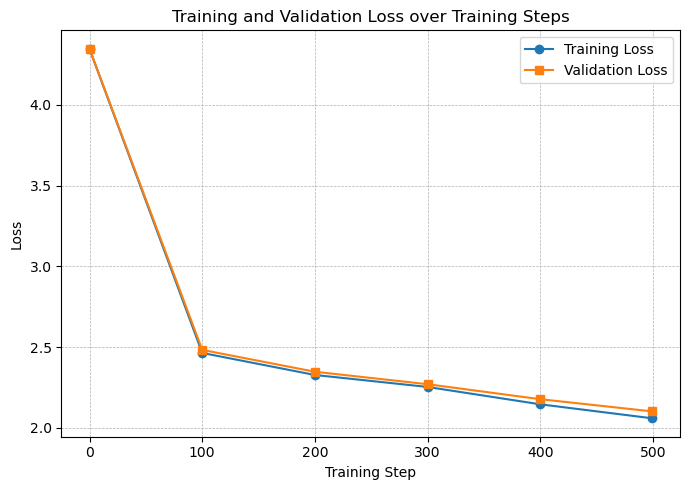

In [30]:
import matplotlib.pyplot as plt

# Eğitim adımları
steps = [0, 100, 200, 300, 400, 499]

# Kayıp değerleri (log çıktılarından alınmıştır)
train_loss = [4.3475, 2.4635, 2.3270, 2.2528, 2.1452, 2.0589]
val_loss   = [4.3479, 2.4824, 2.3470, 2.2698, 2.1769, 2.1016]

# Grafik oluşturma
plt.figure(figsize=(7, 5))
plt.plot(steps, train_loss, marker='o', label='Training Loss')
plt.plot(steps, val_loss, marker='s', label='Validation Loss')

# Eksen etiketleri ve başlık
plt.xlabel('Training Step')
plt.ylabel('Loss')
plt.title('Training and Validation Loss over Training Steps')

# Izgara ve lejant
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.legend()

# Görselleştirme
plt.tight_layout()
plt.savefig('training_validation_loss.svg')
plt.show()

In [28]:
# Modeli Değerlendirme Moduna Al
model.eval()

# 1. Başlangıç Bağlamı (Boş bir satır ile başlatıyoruz)
# start_str = "\n"
# context = torch.tensor([encode(start_str)], dtype=torch.long, device=device)
# VEYA basitçe 0 (yeni satır karakteri genelde baştadır) ile başlatabiliriz:
context = torch.zeros((1, 1), dtype=torch.long, device=device)

print("--- MODEL ÜRETİMİ BAŞLIYOR ---\n")

# 2. Üretim (500 karakter üretelim)
generated_ids = model.generate(context, max_new_tokens=50)[0].tolist()

# 3. Metne Çevirme
generated_text = decode(generated_ids)

print(generated_text)
print("\n------------------------------")

--- MODEL ÜRETİMİ BAŞLIYOR ---


wis Douporoth,
to chas dased tor, goounds aw sthu

------------------------------
